<a href="https://colab.research.google.com/github/alelopez9411-ux/proyecto-pronostico-demanda/blob/main/notebooks/pronostico_demanda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

df = pd.read_csv("ventas_diarias.csv", parse_dates=["fecha"])
print(df.shape)
df.head()

(1096, 8)


,fecha,ventas_unidades,temperatura_c,lluvia_mm,promocion,descuento_pct,festivo,precio_unitario
0,2023-01-01,260,25.6,13.2,0,0,1,8500
1,2023-01-02,206,26.6,0.0,0,0,0,8500
2,2023-01-03,220,25.8,0.0,0,0,0,8500
3,2023-01-04,192,22.5,0.0,0,0,0,8500
4,2023-01-05,205,21.8,7.9,0,0,0,8500


In [2]:
df.info()
print()
print(df.isna().sum())
print()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1096 entries, 0 to 1095
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   fecha            1096 non-null   datetime64[ns]
 1   ventas_unidades  1096 non-null   int64         
 2   temperatura_c    1078 non-null   float64       
 3   lluvia_mm        1090 non-null   float64       
 4   promocion        1096 non-null   int64         
 5   descuento_pct    1096 non-null   int64         
 6   festivo          1096 non-null   int64         
 7   precio_unitario  1096 non-null   int64         
dtypes: datetime64[ns](1), float64(2), int64(5)
memory usage: 68.6 KB

fecha               0
ventas_unidades     0
temperatura_c      18
lluvia_mm           6
promocion           0
descuento_pct       0
festivo             0
precio_unitario     0
dtype: int64



,fecha,ventas_unidades,temperatura_c,lluvia_mm,promocion,descuento_pct,festivo,precio_unitario
count,1096,1096.000000,1078.000000,1090.000000,1096.000000,1096.000000,1096.000000,1096.000000
mean,2024-07-01 12:00:00,255.073905,24.988219,1.872661,0.163321,2.363139,0.048358,8299.133212
min,2023-01-01 00:00:00,0.000000,19.400000,0.000000,0.000000,0.000000,0.000000,6800.000000
25%,2023-10-01 18:00:00,224.000000,23.700000,0.000000,0.000000,0.000000,0.000000,8500.000000
50%,2024-07-01 12:00:00,248.000000,25.000000,0.000000,0.000000,0.000000,0.000000,8500.000000
75%,2025-04-01 06:00:00,280.250000,26.300000,0.000000,0.000000,0.000000,0.000000,8500.000000
max,2025-12-31 00:00:00,1012.000000,30.000000,34.100000,1.000000,20.000000,1.000000,8500.000000
std,NaN,48.075350,1.868708,4.909621,0.369827,5.570591,0.214619,473.500205


In [3]:
print(df[df["ventas_unidades"] == 0])
print()
print(df[df["ventas_unidades"] > 600])
print()
print(df[df["temperatura_c"].isna()].head())

         fecha  ventas_unidades  temperatura_c  lluvia_mm  promocion  \
951 2025-08-09                0           24.9        0.0          0   

     descuento_pct  festivo  precio_unitario  
951              0        0             8500  

         fecha  ventas_unidades  temperatura_c  lluvia_mm  promocion  \
264 2023-09-22             1012           23.5        0.0          0   

     descuento_pct  festivo  precio_unitario  
264              0        0             8500  

         fecha  ventas_unidades  temperatura_c  lluvia_mm  promocion  \
5   2023-01-06              273            NaN        0.0          1   
25  2023-01-26              263            NaN        0.0          0   
120 2023-05-01              205            NaN        0.0          0   
233 2023-08-22              239            NaN        0.0          1   
293 2023-10-21              278            NaN        8.5          0   

     descuento_pct  festivo  precio_unitario  
5               10        0             

In [4]:
import numpy as np

df_limpio = df.copy()

# 1) Marcar como vacíos los dos valores erróneos de ventas
mask = (df_limpio["ventas_unidades"] == 0) | (df_limpio["ventas_unidades"] > 600)
df_limpio.loc[mask, "ventas_unidades"] = np.nan

# 2) Rellenar con el promedio del mismo día de la semana anterior y siguiente
vecinos = (df_limpio["ventas_unidades"].shift(7) + df_limpio["ventas_unidades"].shift(-7)) / 2
df_limpio["ventas_unidades"] = df_limpio["ventas_unidades"].fillna(vecinos)

# 3) Temperatura: interpolar entre el día anterior y el siguiente
df_limpio["temperatura_c"] = df_limpio["temperatura_c"].interpolate()

# 4) Lluvia: rellenar con 0 (la mayoría de los días no llueve)
df_limpio["lluvia_mm"] = df_limpio["lluvia_mm"].fillna(0)

print(df_limpio.isna().sum())
print(df_limpio.loc[[264, 951], ["fecha", "ventas_unidades"]])

fecha              0
ventas_unidades    0
temperatura_c      0
lluvia_mm          0
promocion          0
descuento_pct      0
festivo            0
precio_unitario    0
dtype: int64
         fecha  ventas_unidades
264 2023-09-22            246.5
951 2025-08-09            311.5


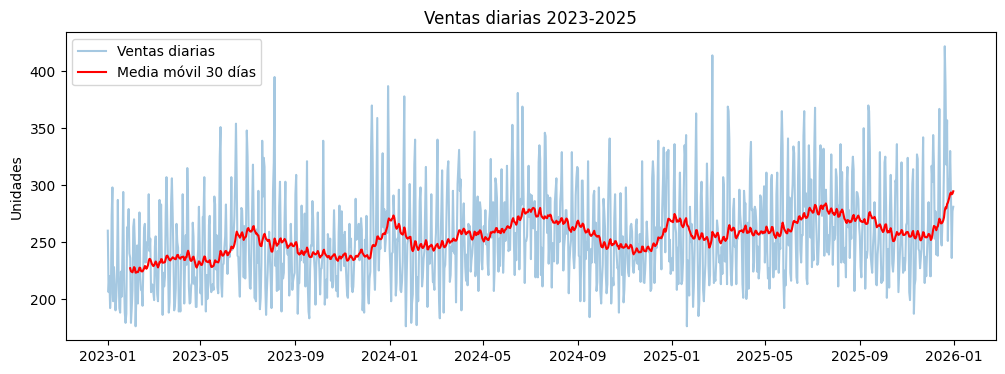

In [5]:
import matplotlib.pyplot as plt

serie = df_limpio.set_index("fecha")["ventas_unidades"]

plt.figure(figsize=(12, 4))
plt.plot(serie, alpha=0.4, label="Ventas diarias")
plt.plot(serie.rolling(30).mean(), color="red", label="Media móvil 30 días")
plt.title("Ventas diarias 2023-2025")
plt.ylabel("Unidades")
plt.legend()
plt.show()

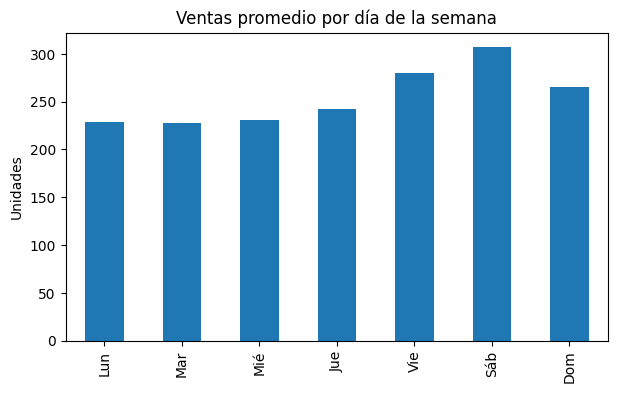

Lun    228.9
Mar    227.7
Mié    230.8
Jue    242.7
Vie    280.4
Sáb    307.0
Dom    265.6
Name: ventas_unidades, dtype: float64


In [6]:
df_limpio["dia_semana"] = df_limpio["fecha"].dt.dayofweek   # 0 = lunes, 6 = domingo

promedio = df_limpio.groupby("dia_semana")["ventas_unidades"].mean()
promedio.index = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

promedio.plot(kind="bar", figsize=(7, 4), title="Ventas promedio por día de la semana")
plt.ylabel("Unidades")
plt.show()

print(promedio.round(1))

In [7]:
print(df_limpio.groupby("promocion")["ventas_unidades"].mean().round(1))
print()
print(df_limpio.groupby("festivo")["ventas_unidades"].mean().round(1))
print()
print(df_limpio[["ventas_unidades", "temperatura_c", "lluvia_mm", "descuento_pct"]].corr().round(2))

promocion
0    247.3
1    292.1
Name: ventas_unidades, dtype: float64

festivo
0    254.3
1    261.6
Name: ventas_unidades, dtype: float64

                 ventas_unidades  temperatura_c  lluvia_mm  descuento_pct
ventas_unidades             1.00           0.22      -0.08           0.43
temperatura_c               0.22           1.00      -0.00           0.01
lluvia_mm                  -0.08          -0.00       1.00           0.01
descuento_pct               0.43           0.01       0.01           1.00


In [8]:
import numpy as np

train = df_limpio.iloc[:-90]
test = df_limpio.iloc[-90:]
print(train["fecha"].max(), test["fecha"].min(), test["fecha"].max())

def mae(real, pred):
    return np.mean(np.abs(real - pred))

def rmse(real, pred):
    return np.sqrt(np.mean((real - pred) ** 2))

y_real = test["ventas_unidades"].values

# Modelo 1 (ingenuo): repetir el último valor conocido
pred_naive = np.repeat(train["ventas_unidades"].iloc[-1], len(test))

# Modelo 2 (estacional ingenuo): repetir la última semana conocida
ultima_semana = train["ventas_unidades"].iloc[-7:].values
pred_estacional = np.tile(ultima_semana, 13)[:len(test)]

print("Naive           -> MAE:", round(mae(y_real, pred_naive), 1), " RMSE:", round(rmse(y_real, pred_naive), 1))
print("Estacional 7d   -> MAE:", round(mae(y_real, pred_estacional), 1), " RMSE:", round(rmse(y_real, pred_estacional), 1))

2025-10-02 00:00:00 2025-10-03 00:00:00 2025-12-31 00:00:00
Naive           -> MAE: 37.4  RMSE: 47.6
Estacional 7d   -> MAE: 30.5  RMSE: 42.4


In [9]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

serie_train = train.set_index("fecha")["ventas_unidades"].asfreq("D")

modelo_hw = ExponentialSmoothing(
    serie_train,
    trend="add",
    seasonal="mul",
    seasonal_periods=7
).fit()

pred_hw = modelo_hw.forecast(90).values

print("Holt-Winters    -> MAE:", round(mae(y_real, pred_hw), 1), " RMSE:", round(rmse(y_real, pred_hw), 1))

Holt-Winters    -> MAE: 25.5  RMSE: 35.2


In [10]:
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

def crear_features(d):
    X = pd.DataFrame(index=d.index)
    X["dia_semana"] = d["fecha"].dt.dayofweek
    X["mes"] = d["fecha"].dt.month
    X["dia_anio"] = d["fecha"].dt.dayofyear
    X["t"] = (d["fecha"] - df_limpio["fecha"].min()).dt.days
    X["festivo"] = d["festivo"]
    X["promocion"] = d["promocion"]
    X["descuento_pct"] = d["descuento_pct"]
    return X

X_train = crear_features(train)
X_test = crear_features(test)

modelo_gb = HistGradientBoostingRegressor(random_state=42)
modelo_gb.fit(X_train, train["ventas_unidades"])
pred_gb = modelo_gb.predict(X_test)

print("Gradient Boosting -> MAE:", round(mae(y_real, pred_gb), 1), " RMSE:", round(rmse(y_real, pred_gb), 1))

Gradient Boosting -> MAE: 19.6  RMSE: 26.4


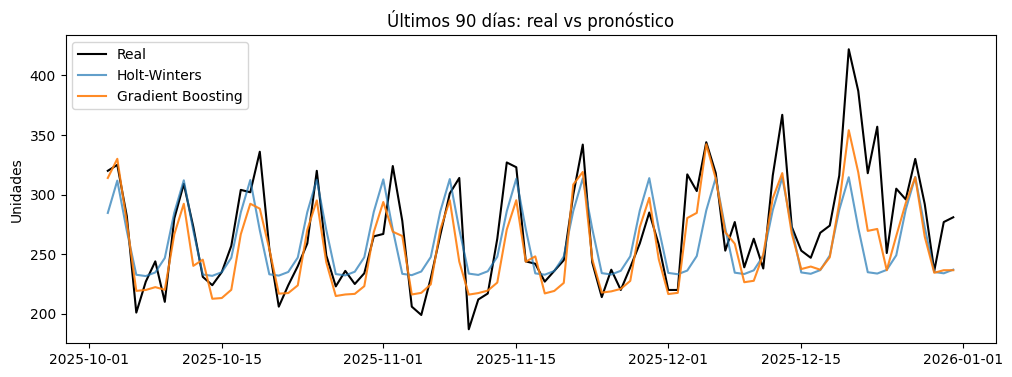

        fecha   real  pred_gb  error  promocion  festivo
81 2025-12-23  357.0    271.0   86.0          1        0
37 2025-11-09  314.0    244.0   70.0          0        0
79 2025-12-21  387.0    319.0   68.0          1        0
78 2025-12-20  422.0    354.0   68.0          1        0
42 2025-11-14  327.0    271.0   56.0          0        0
30 2025-11-02  324.0    269.0   55.0          1        0
71 2025-12-13  367.0    318.0   49.0          0        0
80 2025-12-22  318.0    270.0   48.0          1        0


In [11]:
fechas_test = test["fecha"].values

plt.figure(figsize=(12, 4))
plt.plot(fechas_test, y_real, label="Real", color="black")
plt.plot(fechas_test, pred_hw, label="Holt-Winters", alpha=0.7)
plt.plot(fechas_test, pred_gb, label="Gradient Boosting", alpha=0.9)
plt.title("Últimos 90 días: real vs pronóstico")
plt.ylabel("Unidades")
plt.legend()
plt.show()

errores = pd.DataFrame({
    "fecha": test["fecha"].values,
    "real": y_real,
    "pred_gb": pred_gb.round(0),
    "error": (y_real - pred_gb).round(0),
    "promocion": test["promocion"].values,
    "festivo": test["festivo"].values,
})
print(errores.reindex(errores["error"].abs().sort_values(ascending=False).index).head(8))

In [12]:
def crear_features2(d):
    X = crear_features(d)
    X["temperatura_c"] = d["temperatura_c"]
    X["lluvia_mm"] = d["lluvia_mm"]
    return X

modelo_gb2 = HistGradientBoostingRegressor(random_state=42)
modelo_gb2.fit(crear_features2(train), train["ventas_unidades"])
pred_gb2 = modelo_gb2.predict(crear_features2(test))

print("GB sin clima  -> MAE:", round(mae(y_real, pred_gb), 1), " RMSE:", round(rmse(y_real, pred_gb), 1), " Sesgo:", round(np.mean(y_real - pred_gb), 1))
print("GB con clima  -> MAE:", round(mae(y_real, pred_gb2), 1), " RMSE:", round(rmse(y_real, pred_gb2), 1), " Sesgo:", round(np.mean(y_real - pred_gb2), 1))

GB sin clima  -> MAE: 19.6  RMSE: 26.4  Sesgo: 14.1
GB con clima  -> MAE: 17.7  RMSE: 24.5  Sesgo: 11.3


In [13]:
X_train2 = crear_features2(train)
X_test2 = crear_features2(test)

# --- Versión A: predecir el logaritmo de las ventas ---
log_y = np.log(train["ventas_unidades"])

modelo_a = HistGradientBoostingRegressor(random_state=42)
modelo_a.fit(X_train2, log_y)
pred_a = np.exp(modelo_a.predict(X_test2))

# --- Versión B: logaritmo + quitar la tendencia antes de entrenar ---
coef = np.polyfit(X_train2["t"], log_y, 1)
tend_train = np.polyval(coef, X_train2["t"])
tend_test = np.polyval(coef, X_test2["t"])

modelo_b = HistGradientBoostingRegressor(random_state=42)
modelo_b.fit(X_train2, log_y - tend_train)
pred_b = np.exp(modelo_b.predict(X_test2) + tend_test)

for nombre, p in [("GB con clima", pred_gb2), ("A: log", pred_a), ("B: log + tendencia", pred_b)]:
    print(f"{nombre:20s} MAE: {mae(y_real, p):.1f}  RMSE: {rmse(y_real, p):.1f}  Sesgo: {np.mean(y_real - p):.1f}")

GB con clima         MAE: 17.7  RMSE: 24.5  Sesgo: 11.3
A: log               MAE: 18.7  RMSE: 26.0  Sesgo: 12.9
B: log + tendencia   MAE: 16.8  RMSE: 23.0  Sesgo: 8.3


In [14]:
import warnings
warnings.filterwarnings("ignore")

def pronostico_estacional(train_d, h):
    ult = train_d["ventas_unidades"].iloc[-7:].values
    return np.tile(ult, h // 7 + 1)[:h]

def pronostico_hw(train_d, h):
    s = train_d.set_index("fecha")["ventas_unidades"].asfreq("D")
    m = ExponentialSmoothing(s, trend="add", seasonal="mul", seasonal_periods=7).fit()
    return m.forecast(h).values

def pronostico_gb(train_d, test_d):
    Xtr = crear_features2(train_d)
    Xte = crear_features2(test_d)
    log_y = np.log(train_d["ventas_unidades"])
    coef = np.polyfit(Xtr["t"], log_y, 1)
    m = HistGradientBoostingRegressor(random_state=42)
    m.fit(Xtr, log_y - np.polyval(coef, Xtr["t"]))
    return np.exp(m.predict(Xte) + np.polyval(coef, Xte["t"]))

H = 28
filas = []

for o in range(365, len(df_limpio) - H + 1, 28):
    tr = df_limpio.iloc[:o]
    te = df_limpio.iloc[o:o + H]
    real = te["ventas_unidades"].values

    preds = {
        "Estacional 7d": pronostico_estacional(tr, H),
        "Holt-Winters": pronostico_hw(tr, H),
        "GB": pronostico_gb(tr, te),
    }

    for nombre, p in preds.items():
        for h in range(H):
            filas.append({"origen": o, "modelo": nombre, "horizonte": h + 1,
                          "real": real[h], "pred": p[h]})

res = pd.DataFrame(filas)
res["error_abs"] = (res["real"] - res["pred"]).abs()

print("Número de ventanas:", res["origen"].nunique())
print()
print(res.groupby("modelo")["error_abs"].mean().round(1))
print()
print(res[res["horizonte"].isin([1, 7, 14, 28])].groupby(["modelo", "horizonte"])["error_abs"].mean().unstack().round(1))

Número de ventanas: 26

modelo
Estacional 7d    32.8
GB               15.8
Holt-Winters     24.1
Name: error_abs, dtype: float64

horizonte        1     7     14    28
modelo                               
Estacional 7d  24.9  31.5  32.8  28.2
GB             13.9  19.1  16.0  20.0
Holt-Winters   18.9  27.7  18.5  23.0


In [15]:
res["tramo"] = pd.cut(res["horizonte"], bins=[0, 7, 14, 21, 28], labels=["1-7", "8-14", "15-21", "22-28"])
res["smape"] = 100 * 2 * res["error_abs"] / (res["real"].abs() + res["pred"].abs())

print("MAE por tramo de horizonte (días):")
print(res.groupby(["modelo", "tramo"], observed=True)["error_abs"].mean().unstack().round(1))
print()
print("sMAPE promedio (%):")
print(res.groupby("modelo")["smape"].mean().round(1))
print()
print("sMAPE por tramo (%):")
print(res.groupby(["modelo", "tramo"], observed=True)["smape"].mean().unstack().round(1))

MAE por tramo de horizonte (días):
tramo           1-7  8-14  15-21  22-28
modelo                                 
Estacional 7d  34.2  31.6   31.3   34.0
GB             14.8  15.8   14.9   17.7
Holt-Winters   24.4  22.0   23.8   26.2

sMAPE promedio (%):
modelo
Estacional 7d    12.4
GB                6.1
Holt-Winters      9.2
Name: smape, dtype: float64

sMAPE por tramo (%):
tramo           1-7  8-14  15-21  22-28
modelo                                 
Estacional 7d  12.8  12.0   11.8   12.9
GB              5.7   6.2    5.6    6.7
Holt-Winters    9.2   8.6    8.9   10.0


In [16]:
def pronostico_gb_modo(train_d, test_d, modo):
    Xtr = crear_features2(train_d)
    Xte = crear_features2(test_d)

    if modo == "sin_clima":
        cols = [c for c in Xtr.columns if c not in ("temperatura_c", "lluvia_mm")]
        Xtr, Xte = Xtr[cols], Xte[cols]
    elif modo == "clima_promedio":
        prom = train_d.groupby(train_d["fecha"].dt.month)[["temperatura_c", "lluvia_mm"]].mean()
        meses = test_d["fecha"].dt.month
        Xte["temperatura_c"] = meses.map(prom["temperatura_c"]).values
        Xte["lluvia_mm"] = meses.map(prom["lluvia_mm"]).values

    log_y = np.log(train_d["ventas_unidades"])
    coef = np.polyfit(Xtr["t"], log_y, 1)
    m = HistGradientBoostingRegressor(random_state=42)
    m.fit(Xtr, log_y - np.polyval(coef, Xtr["t"]))
    return np.exp(m.predict(Xte) + np.polyval(coef, Xte["t"]))

modos = ["real", "sin_clima", "clima_promedio"]
filas2 = []

for o in range(365, len(df_limpio) - H + 1, 28):
    tr = df_limpio.iloc[:o]
    te = df_limpio.iloc[o:o + H]
    real = te["ventas_unidades"].values
    for modo in modos:
        p = pronostico_gb_modo(tr, te, modo)
        filas2.append({"modo": modo,
                       "mae": np.mean(np.abs(real - p)),
                       "smape": np.mean(100 * 2 * np.abs(real - p) / (np.abs(real) + np.abs(p)))})

res2 = pd.DataFrame(filas2)
print(res2.groupby("modo")[["mae", "smape"]].mean().round(2))

                  mae  smape
modo                        
clima_promedio  16.92   6.46
real            15.80   6.06
sin_clima       17.65   6.76


MAE base: 16.8

dia_semana       20.03
promocion         5.94
dia_anio          4.58
temperatura_c     1.61
festivo           0.99
lluvia_mm         0.83
descuento_pct     0.62
t                 0.00
mes              -0.11
dtype: float64


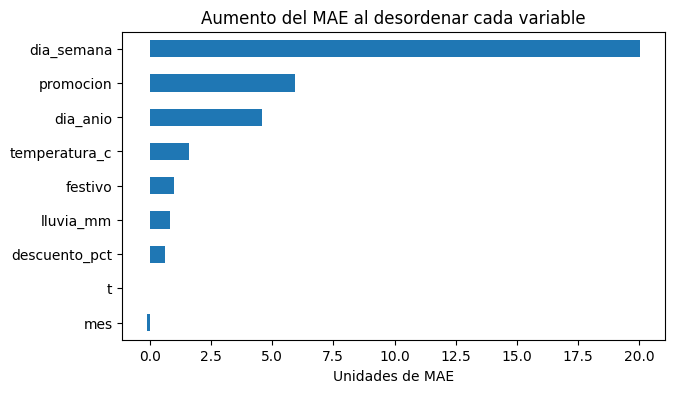

In [17]:
rng = np.random.default_rng(42)

base = mae(y_real, np.exp(modelo_b.predict(X_test2) + tend_test))

imp = {}
for col in X_test2.columns:
    errores_col = []
    for _ in range(10):
        Xp = X_test2.copy()
        Xp[col] = rng.permutation(Xp[col].values)
        p = np.exp(modelo_b.predict(Xp) + tend_test)
        errores_col.append(mae(y_real, p))
    imp[col] = np.mean(errores_col) - base

imp = pd.Series(imp).sort_values(ascending=False)
print("MAE base:", round(base, 1))
print()
print(imp.round(2))

imp.sort_values().plot(kind="barh", figsize=(7, 4), title="Aumento del MAE al desordenar cada variable")
plt.xlabel("Unidades de MAE")
plt.show()